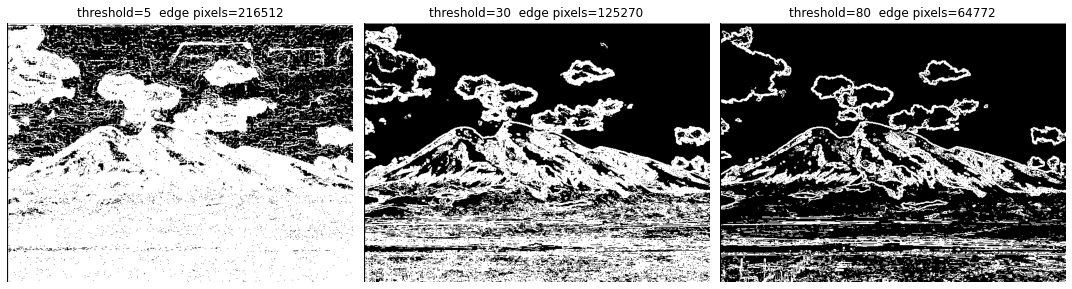

In [1]:
from pynq import Overlay, allocate
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

ol = Overlay('/home/xilinx/jupyter_notebooks/pynq_sobel/system_wrapper2.bit')
dma = ol.axi_dma_0
sobel_ip = ol.sobel_filter_0

img = Image.open('/home/xilinx/jupyter_notebooks/pynq_sobel/img1.png').convert('L').resize((640, 480))
src_np = np.array(img, dtype=np.uint8)

in_buf  = allocate(shape=(480, 640), dtype=np.uint8)
out_buf = allocate(shape=(480, 640), dtype=np.uint8)
in_buf[:] = src_np

sobel_ip.write(0x10, 480)
sobel_ip.write(0x18, 640)

results = {}

for thresh in [5, 30, 80]:
    out_buf[:] = 0  # 清空缓冲
    sobel_ip.write(0x20, thresh)
    sobel_ip.write(0x00, 0x01)
    dma.recvchannel.transfer(out_buf)
    dma.sendchannel.transfer(in_buf)
    dma.sendchannel.wait()
    dma.recvchannel.wait()
    results[thresh] = np.copy(out_buf)  # ← 关键：立即复制

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, thresh in enumerate([5, 30, 80]):
    axes[i].imshow(results[thresh], cmap='gray')
    axes[i].set_title(f'threshold={thresh}  edge pixels={np.count_nonzero(results[thresh])}')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('/home/xilinx/jupyter_notebooks/pynq_sobel/threshold_compare.png', dpi=150)
plt.show()